# Notebook 7: False alarms on images without weapons

BD-LW has no "no weapon" class, so a classifier always outputs one of the six weapon classes. This notebook measures how often the trained E1 models would raise a **false alarm** on images that contain no weapon, and whether the model's **confidence** separates weapons from non-weapons.

No training is done. Each model is the 5-fold ensemble of recipe F from Notebook 2 (with flip test-time augmentation, as in the paper), and the confidence is temperature-scaled with the temperatures from the calibration analysis.

## What it computes
| Output | Meaning |
|---|---|
| False-alarm rate at 95% weapon recall | Threshold set so that 95% of the BD-LW test weapons are still flagged; share of no-weapon images above it |
| AUROC | How well the confidence separates the 419 weapon test images from the no-weapon images (1.0 = perfect, 0.5 = chance) |
| Rate per subfolder | `look_alike` vs `regular_using_things` |
| Predicted class | Which weapon class the no-weapon images are mistaken for |

## Inputs (Add Input)
| Input | Used for |
|---|---|
| Stage 0 output | the 419 locked test images (weapons) |
| Notebook 2 output, final version | `results/all/<model>/F/weights/fold0.pt ... fold4.pt`, `norm.json`, `summary_all.csv` |
| **No-weapon dataset** (Add Input -> Your Datasets) | folder `No weapon` with subfolders `look_alike` and `regular_using_things` |
| *(optional)* Notebook 3 output | `T12_calibration.csv` (temperatures); otherwise the values from the paper are used |

Accelerator: **GPU T4** (about 10 min). On CPU it takes about 1.5 h.

## Outputs (`/kaggle/working/no_weapon/`, zipped as `no_weapon.zip`)
`no_weapon_summary.csv`, `no_weapon_per_subfolder.csv`, `no_weapon_predicted_class.csv`, `no_weapon_per_image.csv`, and the figures `no_weapon_confidence.pdf/png` and `no_weapon_examples.pdf/png`.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("timm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
import os, json, math, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.metrics import roc_auc_score
import torch, torch.nn.functional as F_, timm
warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ON_KAGGLE = Path("/kaggle/input").is_dir()
INPUT_ROOT = Path("/kaggle/input") if ON_KAGGLE else Path(r"H:\BD Weapon Inputs")
OUT = (Path("/kaggle/working") if ON_KAGGLE else Path(r"H:\BD Weapon Analysis")) / "no_weapon"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["resnet50", "efficientnet_b0", "convnext_tiny", "vit_small_patch16_224"]
NAME = {"resnet50": "ResNet-50", "efficientnet_b0": "EfficientNet-B0", "convnext_tiny": "ConvNeXt-Tiny",
        "vit_small_patch16_224": "ViT-S/16"}
TARGET_RECALL = 0.95           # share of weapon test images that must stay above the threshold
# temperatures from the paper (Table S8); replaced by T12_calibration.csv if Notebook 3 output is attached
T_DEFAULT = {"resnet50": 0.3513, "efficientnet_b0": 0.3685, "convnext_tiny": 0.3919, "vit_small_patch16_224": 0.3588}
IMG_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff", ".heic", ".jfif"}
print("device:", DEVICE)

def walk_find(base, predicate, skip=("standardized", "cutouts", "masks", "figures", "weights")):
    for dirpath, dirnames, filenames in os.walk(base, followlinks=True):
        hit = predicate(Path(dirpath), filenames)
        if hit:
            return hit
        dirnames[:] = [x for x in dirnames if x not in skip]
    return None

STAGE0 = walk_find(INPUT_ROOT, lambda d, f: d.parent if ("manifest.csv" in f and d.name == "metadata"
                                                        and d.parent.name == "stage0") else None)
RES = walk_find(INPUT_ROOT, lambda d, f: d if ("summary_all.csv" in f and d.name == "all"
                                              and d.parent.name == "results") else None)
NOW = walk_find(INPUT_ROOT, lambda d, f: d if (d / "look_alike").is_dir() and (d / "regular_using_things").is_dir() else None,
                skip=("standardized", "cutouts", "masks", "figures", "weights", "results"))
T12 = walk_find(INPUT_ROOT, lambda d, f: d / "T12_calibration.csv" if "T12_calibration.csv" in f else None)
assert STAGE0, "Stage 0 output not found (Add Input -> Your Work -> Stage 0 notebook)."
assert RES, "Notebook 2 output (results/all) not found (Add Input -> Your Work -> Notebook 2)."
assert NOW, "No-weapon dataset not found: it needs the subfolders 'look_alike' and 'regular_using_things'."
print("Stage 0      :", STAGE0); print("Notebook 2   :", RES); print("No-weapon set:", NOW)

T_MODEL = dict(T_DEFAULT)
if T12:
    t = pd.read_csv(T12).set_index("model").temperature
    T_MODEL.update({m: float(t[m]) for m in MODELS if m in t.index})
    print("Temperatures from", T12)
print({NAME[m]: round(T_MODEL[m], 3) for m in MODELS})

manifest = pd.read_csv(STAGE0 / "metadata" / "manifest.csv", dtype={"image_id": str})
CLASS_MAP = json.loads((STAGE0 / "metadata" / "class_map.json").read_text())
CLASSES = sorted(CLASS_MAP, key=CLASS_MAP.get)
test = manifest[manifest.split == "test"].reset_index(drop=True)
test["y"] = test.label.map(CLASS_MAP)

rows, bad = [], []
for sub in ("look_alike", "regular_using_things"):
    for p in sorted((NOW / sub).rglob("*")):
        if p.is_file() and p.suffix.lower() in IMG_EXT:
            try:
                Image.open(p).verify()
                rows.append({"subfolder": sub, "path": str(p), "file": p.name})
            except Exception:
                bad.append(p.name)
if bad:
    print(f"Skipped {len(bad)} unreadable file(s) (convert HEIC to JPG if needed):", bad[:10])
neg = pd.DataFrame(rows)
print(f"Weapon test images: {len(test)} | no-weapon images: {len(neg)}")
display(neg.subfolder.value_counts().to_frame("images"))

device: cuda
Stage 0      : /kaggle/input/notebooks/arnicasarker/stage0-single-multi-3parts/stage0
Notebook 2   : /kaggle/input/notebooks/arnicasarker/nb2-training-scenarios/results/all
No-weapon set: /kaggle/input/datasets/arnicasarker/no-weapon/No weapon
Temperatures from /kaggle/input/notebooks/arnicasarker/nb3-analysis-scenarios/analysis/tables/T12_calibration.csv
{'ResNet-50': 0.351, 'EfficientNet-B0': 0.368, 'ConvNeXt-Tiny': 0.392, 'ViT-S/16': 0.359}


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Weapon test images: 419 | no-weapon images: 112


,images
subfolder,
look_alike,72
regular_using_things,40


In [2]:
PAD_GRAY = 128
summ = pd.read_csv(RES / "summary_all.csv").drop_duplicates(["model", "pipeline"], keep="last")

def cfg_of(model):
    s = summ[(summ.model == model) & (summ.pipeline == "F")].iloc[0]
    return {"bg": s.cfg_bg, "size": s.cfg_size, "res": int(s.cfg_res), "color": s.cfg_color}

def geometric(rgb, size, res):                     # identical to Notebook 2
    if size == "stretch":
        return cv2.resize(rgb, (res, res), interpolation=cv2.INTER_AREA)
    h, w = rgb.shape[:2]; s = res / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = cv2.resize(rgb, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    out = np.full((res, res, 3), PAD_GRAY, np.uint8)
    t, l = (res - nh) // 2, (res - nw) // 2
    out[t:t + nh, l:l + nw] = small
    return out

def clahe_rgb(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def convert_color(rgb, color):
    if color == "gray":
        return np.repeat(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)[..., None], 3, axis=2)
    if color == "hsv":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV_FULL)
    if color == "lab":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    return rgb

def load_new(path):
    # new photos: apply the EXIF rotation (Stage 0 did this for BD-LW) and limit the long side like Stage 0
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    im.thumbnail((1600, 1600))
    return np.asarray(im)

def build(paths_or_rows, cfg, new=False):
    arr = []
    for r in paths_or_rows:
        rgb = load_new(r) if new else np.asarray(Image.open(STAGE0 / r).convert("RGB"))
        if cfg["color"] == "clahe":
            rgb = clahe_rgb(rgb)
        arr.append(geometric(rgb, cfg["size"], cfg["res"]))
    return np.stack(arr)

@torch.no_grad()
def ensemble_probs(model_name, cache, T):
    # mean over 5 folds and 2 views (original + flip) of softmax(logits / T)
    cfg = cfg_of(model_name)
    norm = json.loads((RES / model_name / "F" / "weights" / "norm.json").read_text())
    folds = sorted(int(p.stem[4:]) for p in (RES / model_name / "F" / "weights").glob("fold*.pt"))
    total = 0
    for k in folds:
        kw = dict(pretrained=False, num_classes=len(CLASSES))
        if model_name.startswith("vit"):
            kw["img_size"] = cfg["res"]
        net = timm.create_model(model_name, **kw)
        sd = torch.load(RES / model_name / "F" / "weights" / f"fold{k}.pt", map_location="cpu")
        net.load_state_dict({a: b.float() for a, b in sd.items()}); net.eval().to(DEVICE)
        mean = torch.tensor(norm[str(k)]["mean"], dtype=torch.float32).view(1, 3, 1, 1)
        std = torch.tensor(norm[str(k)]["std"], dtype=torch.float32).view(1, 3, 1, 1)
        for flip in (False, True):
            out = []
            for i in range(0, len(cache), 32):
                x = np.stack([convert_color(im, cfg["color"]) for im in cache[i:i + 32]])
                x = torch.from_numpy(x).permute(0, 3, 1, 2).float() / 255
                if flip:
                    x = torch.flip(x, dims=[3])
                x = ((x - mean) / std).to(DEVICE)
                with torch.autocast(device_type=DEVICE, enabled=(DEVICE == "cuda")):
                    logits = net(x).float()
                out.append(F_.softmax(logits / T, dim=1).cpu())
            total = total + torch.cat(out).numpy()
        del net; torch.cuda.empty_cache() if DEVICE == "cuda" else None
    return total / (2 * len(folds)), len(folds)

In [3]:
per_img, summary, per_sub, per_cls = [], [], [], []
S_POS = {}
caches = {}
for m in MODELS:
    if not (RES / m / "F" / "weights" / "norm.json").exists():
        print("skip", m, "(no F weights)"); continue
    cfg = cfg_of(m); key = (cfg["size"], cfg["res"], cfg["color"])
    if key not in caches:
        caches[key] = (build(test.path, cfg), build(neg.path, cfg, new=True))
    c_pos, c_neg = caches[key]
    p_pos, nf = ensemble_probs(m, c_pos, T_MODEL[m])
    p_neg, _ = ensemble_probs(m, c_neg, T_MODEL[m])
    s_pos, s_neg = p_pos.max(1), p_neg.max(1)              # confidence = max class probability
    S_POS[m] = s_pos
    acc = (p_pos.argmax(1) == test.y.to_numpy()).mean()
    thr = float(np.quantile(s_pos, 1 - TARGET_RECALL))    # 95% of weapon images stay at or above it
    auroc = roc_auc_score(np.r_[np.ones(len(s_pos)), np.zeros(len(s_neg))], np.r_[s_pos, s_neg])
    fa = s_neg >= thr
    summary.append({"model": NAME[m], "folds": nf, "temperature": round(T_MODEL[m], 3), "weapon_test_acc": acc,
                    "auroc": auroc, "threshold_95recall": thr, "false_alarm_rate_95recall": fa.mean(),
                    "mean_conf_weapon": s_pos.mean(), "mean_conf_no_weapon": s_neg.mean()})
    d = neg.assign(model=NAME[m], pred=[CLASSES[i] for i in p_neg.argmax(1)], confidence=s_neg, false_alarm=fa)
    per_img.append(d)
    for sub, g in d.groupby("subfolder"):
        per_sub.append({"model": NAME[m], "subfolder": sub, "images": len(g), "false_alarm_rate_95recall": g.false_alarm.mean(),
                        "mean_conf": g.confidence.mean()})
    per_cls.append(d.pred.value_counts().reindex(CLASSES, fill_value=0).rename(NAME[m]))
    print(f"{NAME[m]:16s} AUROC {auroc:.3f} | threshold {thr:.3f} | false alarms {fa.mean():.1%} "
          f"({fa.sum()}/{len(fa)}) | weapon test acc {acc:.3f}")

summary = pd.DataFrame(summary); per_img = pd.concat(per_img); per_sub = pd.DataFrame(per_sub)
per_cls = pd.concat(per_cls, axis=1).T
summary.round(4).to_csv(OUT / "no_weapon_summary.csv", index=False)
per_sub.round(4).to_csv(OUT / "no_weapon_per_subfolder.csv", index=False)
per_cls.to_csv(OUT / "no_weapon_predicted_class.csv")
per_img.drop(columns="path").round(4).to_csv(OUT / "no_weapon_per_image.csv", index=False)
display(summary.round(3)); display(per_sub.round(3)); display(per_cls)

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


ResNet-50        AUROC 0.995 | threshold 0.999 | false alarms 0.9% (1/112) | weapon test acc 0.998
EfficientNet-B0  AUROC 0.996 | threshold 0.953 | false alarms 0.0% (0/112) | weapon test acc 1.000
ConvNeXt-Tiny    AUROC 0.997 | threshold 1.000 | false alarms 0.0% (0/112) | weapon test acc 0.998
ViT-S/16         AUROC 0.994 | threshold 1.000 | false alarms 0.9% (1/112) | weapon test acc 1.000


,model,folds,temperature,weapon_test_acc,auroc,threshold_95recall,false_alarm_rate_95recall,mean_conf_weapon,mean_conf_no_weapon
0,ResNet-50,5,0.351,0.998,0.995,0.999,0.009,0.997,0.621
1,EfficientNet-B0,5,0.368,1.000,0.996,0.953,0.000,0.991,0.562
2,ConvNeXt-Tiny,5,0.392,0.998,0.997,1.000,0.000,0.998,0.652
3,ViT-S/16,5,0.359,1.000,0.994,1.000,0.009,0.998,0.668


,model,subfolder,images,false_alarm_rate_95recall,mean_conf
0,ResNet-50,look_alike,72,0.014,0.588
1,ResNet-50,regular_using_things,40,0.000,0.682
2,EfficientNet-B0,look_alike,72,0.000,0.545
3,EfficientNet-B0,regular_using_things,40,0.000,0.591
4,ConvNeXt-Tiny,look_alike,72,0.000,0.639
5,ConvNeXt-Tiny,regular_using_things,40,0.000,0.675
6,ViT-S/16,look_alike,72,0.014,0.611
7,ViT-S/16,regular_using_things,40,0.000,0.769


pred,Churi,Dao,Khor,Kodal,Kural,Shabol
ResNet-50,54,13,7,17,1,20
EfficientNet-B0,41,62,3,2,2,2
ConvNeXt-Tiny,40,12,7,23,6,24
ViT-S/16,36,33,4,10,6,23


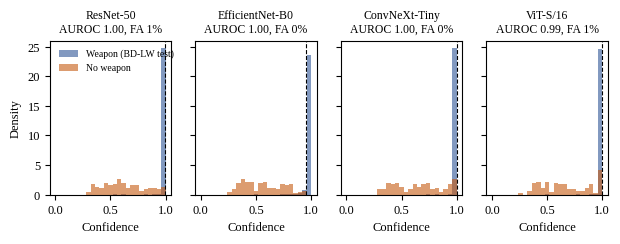

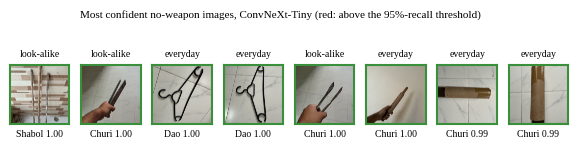

Done. Download /kaggle/working/no_weapon.zip


In [4]:
plt.rcParams.update({"font.family": ["Liberation Serif", "DejaVu Serif"], "pdf.fonttype": 42, "font.size": 9})
# Figure 1: confidence of weapon vs no-weapon images, with the 95%-recall threshold
fig, axes = plt.subplots(1, len(summary), figsize=(7.2, 2.0), sharey=True)
axes = np.atleast_1d(axes)
for ax, m in zip(axes, [m for m in MODELS if NAME[m] in set(summary.model)]):
    s_neg = per_img[per_img.model == NAME[m]].confidence.to_numpy()
    r = summary[summary.model == NAME[m]].iloc[0]
    bins = np.linspace(0, 1, 26)
    s_pos = S_POS[m]
    ax.hist(s_pos, bins=bins, density=True, alpha=0.6, color="#2f5597", label="Weapon (BD-LW test)")
    ax.hist(s_neg, bins=bins, density=True, alpha=0.6, color="#c55a11", label="No weapon")
    ax.axvline(r.threshold_95recall, color="k", ls="--", lw=0.8)
    ax.set_title(f"{NAME[m]}\nAUROC {r.auroc:.2f}, FA {r.false_alarm_rate_95recall:.0%}", fontsize=8.5)
    ax.set_xlabel("Confidence")
axes[0].set_ylabel("Density"); axes[0].legend(fontsize=7, frameon=False, loc="upper left")
for ext in ("pdf", "png"):
    fig.savefig(OUT / f"no_weapon_confidence.{ext}", dpi=300, bbox_inches="tight")
plt.show()

# Figure 2: the most confident false alarms of the best model (lowest false-alarm rate)
best = summary.sort_values(["false_alarm_rate_95recall", "auroc"], ascending=[True, False]).model.iloc[0]
top = per_img[per_img.model == best].sort_values("confidence", ascending=False).head(8)
fig, axes = plt.subplots(1, len(top), figsize=(7.2, 1.45))
for ax, r in zip(np.atleast_1d(axes), top.itertuples()):
    im = load_new(r.path); n = min(im.shape[:2])
    y0, x0 = (im.shape[0] - n) // 2, (im.shape[1] - n) // 2
    ax.imshow(im[y0:y0 + n, x0:x0 + n]); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color("#c00000" if r.false_alarm else "#3a8f3a"); s.set_linewidth(1.5)
    ax.set_title(r.subfolder.replace("regular_using_things", "everyday").replace("look_alike", "look-alike"), fontsize=7)
    ax.set_xlabel(f"{r.pred} {r.confidence:.2f}", fontsize=7)
fig.suptitle(f"Most confident no-weapon images, {best} (red: above the 95%-recall threshold)", fontsize=8, y=1.08)
for ext in ("pdf", "png"):
    fig.savefig(OUT / f"no_weapon_examples.{ext}", dpi=300, bbox_inches="tight")
plt.show()

with zipfile.ZipFile(OUT.parent / "no_weapon.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        z.write(f, f.name)
print("Done. Download /kaggle/working/no_weapon.zip")